# This can be a version of 
https://github.com/bkhelifi/CADS_2025/blob/main/Advanced_handson/joint_crab/joint_crab_start.ipynb

But removing the sampling aspect

# Multi-instrument energy-scale systematic

## Joint spectrum fit with systematics

In this notebook, we redo the joint Crab spectrum fit including systematics on the per-instrument energy scales. After we show the parameter correlations, and we show a plot illustrating the energy scale shifts for each instrument.

We will start from already reduced datasets and add the HAWC release dataset.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

from gammapy.datasets import Datasets, SpectrumDatasetOnOff
from gammapy.modeling import Fit
from gammapy.modeling.models import Models, PointSpatialModel, LogParabolaSpectralModel, SkyModel, GaussianPrior

## Load datasets
Read the public Crab datasets from [Nigro et al. 2019](https://www.aanda.org/articles/aa/full_html/2019/05/aa34938-18/aa34938-18.html) available in `GAMMAPY_DATA`

In [2]:
instruments = ["fermi", "fact", "magic", "veritas", "hess"] 

path = Path(os.environ["GAMMAPY_DATA"])/ "joint-crab/spectra"

datasets = Datasets()

for instrument in instruments:
    files = list(path.rglob(f"{instrument}/pha_*.fits"))
    for filename in files:
        name=f"_{instrument}_{filename.stem.split('_')[-1]}"
        print(name)
        dataset = SpectrumDatasetOnOff.read(filename).copy(name=name)
        datasets.append(dataset)

_fermi_obs0
_fact_stacked
_magic_obs5029747
_magic_obs5029748
_veritas_obs57993
_veritas_obs54809
_hess_obs23523
_hess_obs23526
_hess_obs23559
_hess_obs23592


Read the HAWC datasets provided

In [3]:
filename = "joint_crab_datasets/hawc_datasets/HAWC_pass4_public_Crab.yaml"
datasets_hawc = datasets.read(filename)
datasets_hawc = [d.copy(name="_hawc_"+d.name) for d in datasets_hawc]

/home/feijen/anaconda3/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/utils/scripts.py:73: UserWarning: Checksum verification failed.
  warnings.warn("Checksum verification failed.", UserWarning)


Add them to the list of datasets

In [4]:
datasets.extend(datasets_hawc)
instruments.append("hawc")

In [5]:
print(datasets)

Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : _fermi_obs0
  Instrument : 
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : _fact_stacked
  Instrument : 
  Models     : 

Dataset 2: 

  Type       : SpectrumDatasetOnOff
  Name       : _magic_obs5029747
  Instrument : 
  Models     : 

Dataset 3: 

  Type       : SpectrumDatasetOnOff
  Name       : _magic_obs5029748
  Instrument : 
  Models     : 

Dataset 4: 

  Type       : SpectrumDatasetOnOff
  Name       : _veritas_obs57993
  Instrument : 
  Models     : 

Dataset 5: 

  Type       : SpectrumDatasetOnOff
  Name       : _veritas_obs54809
  Instrument : 
  Models     : 

Dataset 6: 

  Type       : SpectrumDatasetOnOff
  Name       : _hess_obs23523
  Instrument : 
  Models     : 

Dataset 7: 

  Type       : SpectrumDatasetOnOff
  Name       : _hess_obs23526
  Instrument : 
  Models     : 

Dataset 8: 

  Type       : SpectrumDatasetOnOff
  Name       : _hess_obs2355

## Setting the model and fitting

Here we define only the Crab model. All datasets from Fermi to HESS use ON-OFF statistic, they don't require explicit background models. The HAWC datasets all contain a background map. The latter is determined and constrained on a much larger scale. Correction factors are therefore non-necessary a priori.

In [6]:
crab_position = SkyCoord(83.6324, 22.0174, unit="deg", frame="icrs")

spatial_model = PointSpatialModel.from_position(crab_position)
spatial_model.freeze() # frozen for 1D analysis

# We directly start with a log parabola model
spectral_model = LogParabolaSpectralModel(
    amplitude=1e-12 * u.Unit("cm-2 s-1 TeV-1"),
    alpha=2.,
    beta=0.,
    reference=1 * u.TeV,
)
model = SkyModel(spatial_model=spatial_model, spectral_model=spectral_model, name="crab")

models = Models([model])

In [7]:
datasets.models = [model]

In [8]:
optimize_opts = dict(strategy=1, tolerance=0.1)
fit = Fit(optimize_opts=optimize_opts)

## Performing fit per instrument

Here we want to perform a fit per instrument. In order to create a plot with all the butterfly plots we need valid ranges for the fits. We compute them looking at non empty bins in the non masked region of the dataset.

In [9]:
def get_instrument_datasets(datasets, instrument):
    return Datasets([d for d in datasets if instrument in d.name])

# there could be a more robust way to estimate this. e.g. consider bins with positive excess counts
def determine_valid_range(datasets):
    emin, emax = [], []
    for ds in datasets:
        idx = np.nonzero((ds.counts.data>0)*ds.mask.data)[0]
        idx_min, idx_max = np.min(idx), np.max(idx)
        
        emin.append(ds.counts.geom.axes["energy"].edges[idx_min])
        emax.append(ds.counts.geom.axes["energy"].edges[idx_max])
    return np.min(u.Quantity(emin)), np.max(u.Quantity(emax))        

In [10]:
results = []
for instrument in instruments:
    datasets_instrument = get_instrument_datasets(datasets, instrument)
    datasets_instrument.models = models
    fit_result = fit.run(datasets=datasets_instrument)
    emin, emax = determine_valid_range(datasets_instrument)
    
    result_dict = {}
    result_dict["instrument"] = instrument
    result_dict["fit_result"] = fit_result
    result_dict["emin"] = emin.to("TeV")
    result_dict["emax"] = emax.to("TeV")
    
    results.append(result_dict)

HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found


In [11]:
results

[{'instrument': 'fermi',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d520dc7d0>,
  'emin': <Quantity 0.03162278 TeV>,
  'emax': <Quantity 1.41253754 TeV>},
 {'instrument': 'fact',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d52117770>,
  'emin': <Quantity 0.56234133 TeV>,
  'emax': <Quantity 15.84893192 TeV>},
 {'instrument': 'magic',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d520ef860>,
  'emin': <Quantity 0.07943282 TeV>,
  'emax': <Quantity 12.58925412 TeV>},
 {'instrument': 'veritas',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d5213bd40>,
  'emin': <Quantity 0.15848932 TeV>,
  'emax': <Quantity 28.18382931 TeV>},
 {'instrument': 'hess',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d5216a660>,
  'emin': <Quantity 0.70794578 TeV>,
  'emax': <Quantity 70.79457844 TeV>},
 {'instrument': 'hawc',
  'fit_result': <gammapy.modeling.fit.FitResult at 0x7d5d52f50c80>,
  'emin': <Quantity 1. TeV>,
  'emax': <Quantity 100. TeV>}]

In [12]:
joint_results = fit.run(datasets)
result_dict = {}
result_dict["instrument"] = "joint"
result_dict["fit_result"] = joint_results
result_dict["emin"] = 10*u.GeV
result_dict["emax"] = 100*u.TeV
results.append(result_dict)

## Plot the  Crab nebula SED for individual instrument fits and from the joint fit. 

/home/feijen/anaconda3/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


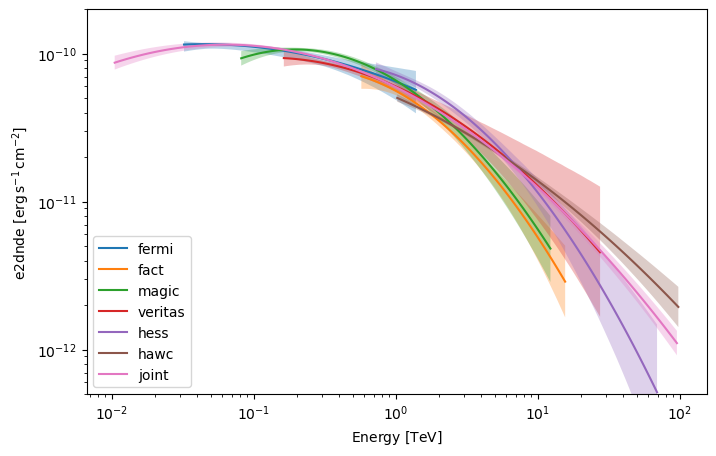

In [13]:
fig, ax = plt.subplots(figsize=(8,5))

plot_kwargs = {
    "sed_type": "e2dnde",
    "ax": ax,
}
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

for result, color in zip(results, colors):
    model = result["fit_result"].models["crab"]
    energy_bounds=u.Quantity([result["emin"], result["emax"]]).to("TeV")
    model.spectral_model.plot(energy_bounds,
        **plot_kwargs, label=result["instrument"], ls="-", color=color
    )
    model.spectral_model.plot_error(energy_bounds,
                                    facecolor=color, alpha=0.3, **plot_kwargs)
ax.set_ylim(5e-13, 2e-10)
ax.legend(loc=3)
plt.show()

## Taking into account inter-calibration systematics

In the following, we will assume that the largest effect is caused by uncertainties in the absolute energy scale.

Gammapy does not provide a simple way to model systematics uncertainties. We can create a simple modified log-parabola model to do it. We show how to do it below.

In [14]:
from gammapy.modeling import Parameter
from gammapy.modeling.models import SpectralModel, SPECTRAL_MODEL_REGISTRY

class ScaledLogParabolaSpectralModel(SpectralModel):
    tag = "ScaledLogParabolaSpectralModel"
    amplitude = Parameter("amplitude", "1e-12 cm-2 s-1 TeV-1", scale_method="scale10", interp="log")
    reference = Parameter("reference", "10 TeV", frozen=True)
    alpha = Parameter("alpha", 2)
    beta = Parameter("beta", 1)
    bias = Parameter("bias", 1)

    @staticmethod
    def evaluate(energy, amplitude, reference, alpha, beta, bias):
        return LogParabolaSpectralModel.evaluate(energy*bias, amplitude, reference, alpha, beta)

    @classmethod
    def from_log_parabola(cls, lpl):
        return cls(amplitude=lpl.amplitude.quantity, 
            alpha=lpl.alpha.quantity,
            beta=lpl.beta.quantity,
            reference=lpl.reference.quantity)

SPECTRAL_MODEL_REGISTRY.append(ScaledLogParabolaSpectralModel)

### Energy scale shift

Lets see how the log-parabolic spectrum is modified by an energy scale shift of $\pm20$%.

For negative energy scale factor bias the spectrum is shifted to lower energies, for positive bias to higher energies.

In [15]:
parent_model = results[-1]["fit_result"].models["crab"].spectral_model

/home/feijen/anaconda3/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


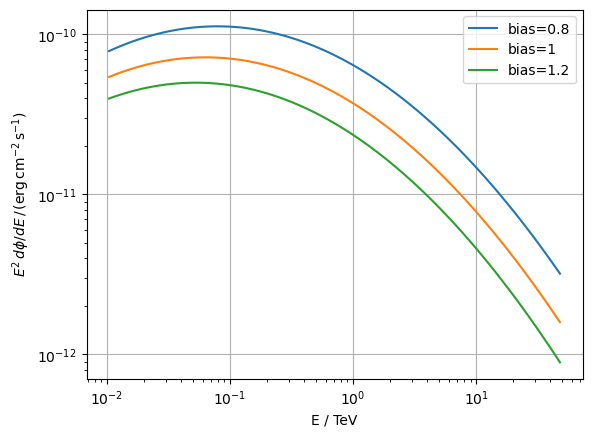

In [16]:
model = ScaledLogParabolaSpectralModel.from_log_parabola(parent_model)
for bias in [0.8, 1, 1.2]:
    model.bias.value = bias
    model.plot([0.01, 50] * u.TeV, energy_power=2, label=f"bias={bias}")

plt.legend()
plt.xlabel("E / TeV")
plt.ylabel(
    r"$E^2\,d\phi/dE\,/\,(\mathrm{erg}\,\mathrm{cm}^{-2}\,\mathrm{s}^{-1})$"
)
plt.grid()

### Apply the new model to all instruments

In [17]:
parent_model = results[-1]["fit_result"].models["crab"].spectral_model
bias_lpl = ScaledLogParabolaSpectralModel.from_log_parabola(parent_model)

models = Models()
for instrument in instruments:
    names = [_.name for _ in get_instrument_datasets(datasets, instrument)]
    
    spec_model = bias_lpl.copy()
    
    # We add a prior of the bias with a reasonable a priori uncertainty
    spec_model.bias.prior = GaussianPrior(mu=1.0,sigma=0.05)
    
    models.append(SkyModel(spectral_model=spec_model, spatial_model=spatial_model , datasets_names=names, name=f"lpl_{instrument}"))


# sharing parameters
for model in models[1:]:
    model.spectral_model.amplitude = models[0].parameters["amplitude"]
    model.spectral_model.alpha = models[0].parameters["alpha"]
    model.spectral_model.beta = models[0].parameters["beta"]

In [18]:
datasets.models = models
result_sys = fit.run(datasets)

In [19]:
result_sys.models

### Nuisance parameter per dataset

Now we can even try to see if we can introduce a nuisance parameter per dataset. After all different runs might suffer from different atmospheric conditions. Different HAWC event types might also suffer from different systematics.

In [20]:
bias_lpl = ScaledLogParabolaSpectralModel.from_log_parabola(parent_model)

models = Models()
for dataset in datasets:
    spec_model = bias_lpl.copy()
    
    # We add a prior of the bias with a reasonable a priori uncertainty
    spec_model.bias.prior = GaussianPrior(mu=1.0,sigma=0.05)
    
    models.append(SkyModel(spectral_model=spec_model, spatial_model=spatial_model , datasets_names=dataset.name, name=f"lpl_{dataset.name}"))


# sharing parameters
for model in models[1:]:
    model.spectral_model.amplitude = models[0].parameters["amplitude"]
    model.spectral_model.alpha = models[0].parameters["alpha"]
    model.spectral_model.beta = models[0].parameters["beta"]

In [21]:
datasets.models = models
result_sys2 = fit.run(datasets)

In [22]:
result_sys2.models

## Plot the bias scale factor for each instrument

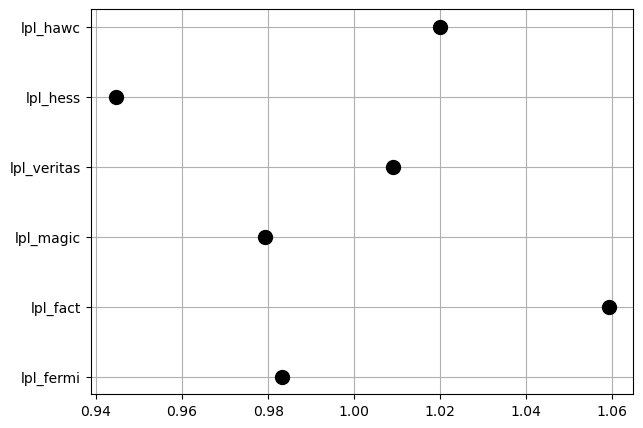

In [23]:
fig, ax = plt.subplots(figsize=(7, 5))
for model in result_sys.models:
    ax.plot([model.parameters['bias'].value], [model.name], ls="-", marker="o", ms=10, color="k")
ax.grid()    

## Plot the bias scale factor for each dataset

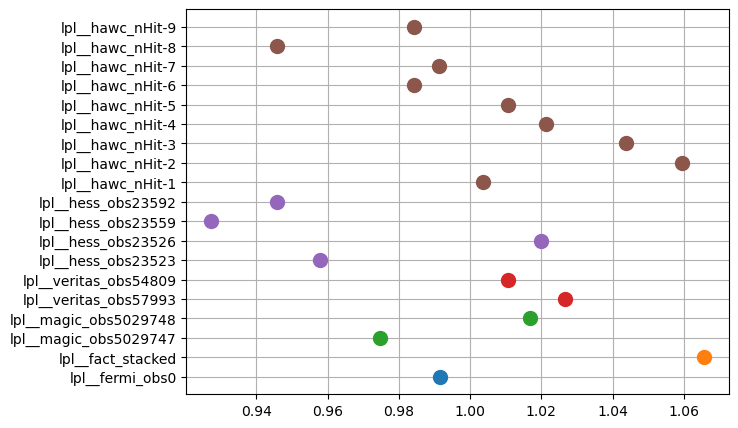

In [24]:
colors = {
    'fermi': colors[0],
    'fact': colors[1],
    'magic': colors[2],
    'veritas': colors[3],
    'hess': colors[4],
    'hawc': colors[5],
}

fig, ax = plt.subplots(figsize=(7, 5))
for model in result_sys2.models:
    color = next(
        (c for key, c in colors.items() if key in model.name.lower()),
        'black'
    )
    ax.plot([model.parameters['bias'].value], [model.name], ls="-", marker="o", ms=10, color=color)
ax.grid()    

Plot 1sigma ellipses

https://github.com/open-gamma-ray-astro/joint-crab/blob/master/2_results.ipynb


### Disclaimer this is claude.ai without me checking anything yet!

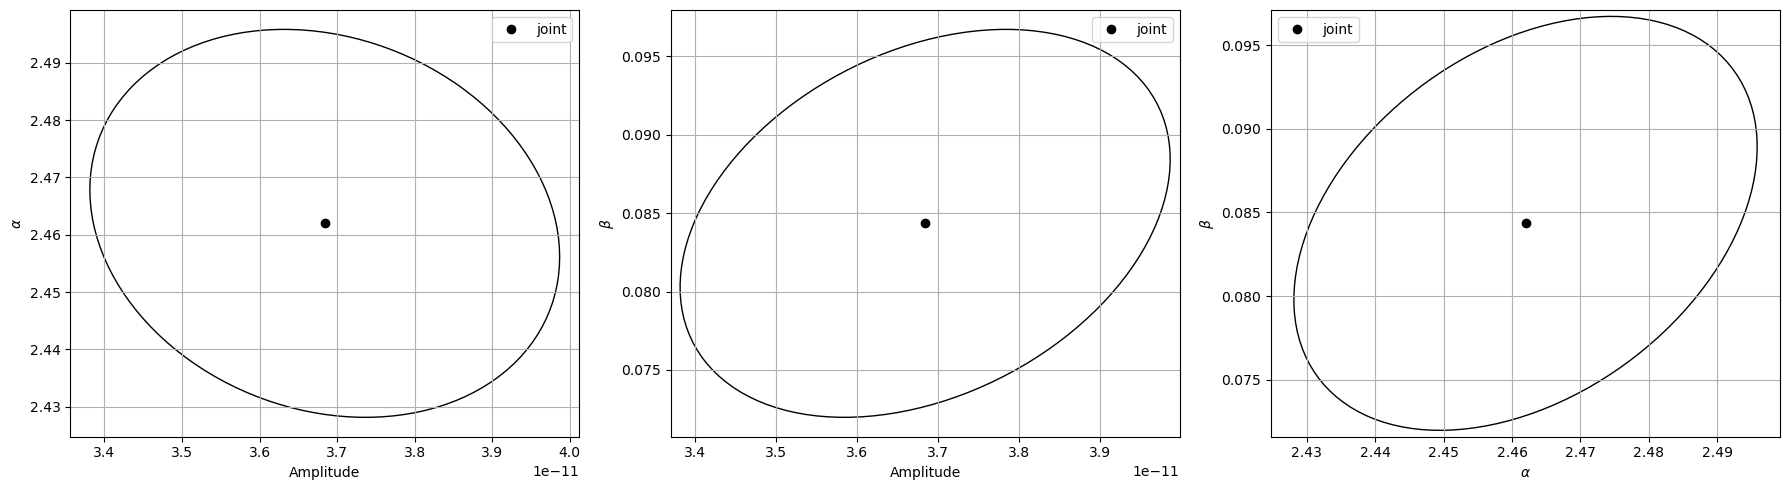

In [25]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2

def plot_covariance_ellipse(ax, model, covariance, x_name, y_name, scale):
    xpar = model.parameters[x_name]
    ypar = model.parameters[y_name]

    # Find parameter indices in the covariance matrix
    idx = [covariance.parameters.index(xpar), covariance.parameters.index(ypar)]

    # Extract the 2x2 covariance matrix
    cov_2d = covariance.data[np.ix_(idx, idx)]

    # Eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(cov_2d)

    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    eigenvalues = np.maximum(eigenvalues, 0)

    # Ellipse orientation
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))

    # Central value
    ax.plot(xpar.value, ypar.value, marker='o', color='k', ls='none', label='joint')

    # Correlated uncertainty ellipse
    ellipse = Ellipse(
        xy=(xpar.value, ypar.value),
        width=2 * scale * np.sqrt(eigenvalues[0]),
        height=2 * scale * np.sqrt(eigenvalues[1]),
        angle=angle,
        fill=None,
        edgecolor='k'
    )

    ax.add_patch(ellipse)


# Get covariance matrix
covariance = result_sys.models.covariance

# 68.27% joint confidence level
scale = np.sqrt(chi2.ppf(0.6827, df=2))

# Model
model = result_sys.models[0]

# Parameter combinations
pairs = [
    ('amplitude', 'alpha'),
    ('amplitude', 'beta'),
    ('alpha', 'beta')
]

labels = {
    'amplitude': 'Amplitude',
    'alpha': r'$\alpha$',
    'beta': r'$\beta$'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x_name, y_name) in zip(axes, pairs):
    plot_covariance_ellipse(
        ax, model, covariance, x_name, y_name, scale
    )
    ax.set_xlabel(labels[x_name])
    ax.set_ylabel(labels[y_name])
    ax.grid()
    ax.legend()
plt.tight_layout()
plt.show()